In [29]:
print("hello")

hello


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
df = pd.read_csv("heart_disease_cleveland.csv")
print("dataset shape: ",df.shape)

dataset shape:  (303, 14)


In [32]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [33]:
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())


Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [34]:
#STATISTICAL SUMMARY

In [35]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


Text(0.5, 0, 'Target (0 = negative, 1 = positive)')

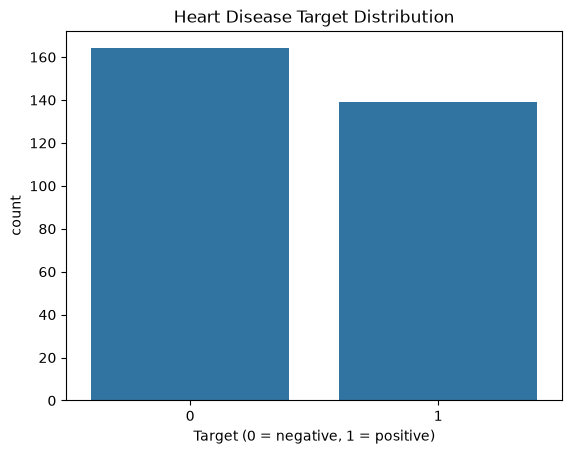

In [36]:
sns.countplot(data=df, x="target")
plt.title("Heart Disease Target Distribution")
plt.xlabel("Target (0 = negative, 1 = positive)")

Text(0.5, 1.0, 'Missing Values in Dataset')

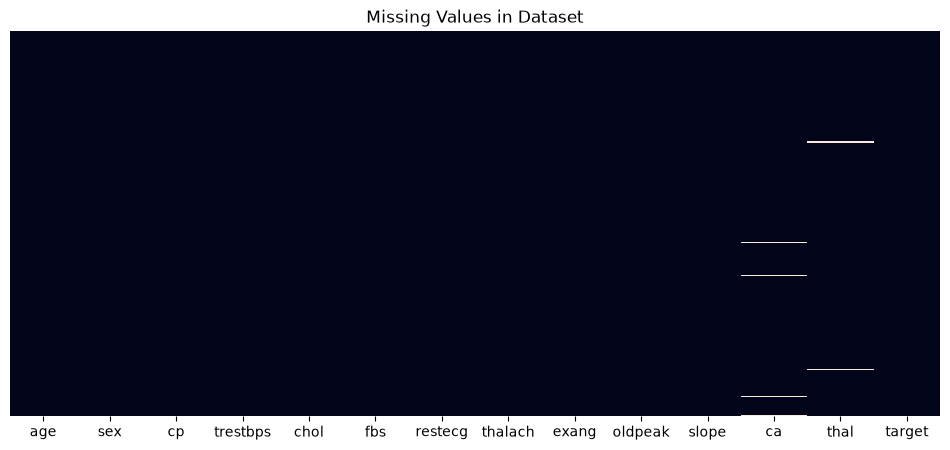

In [37]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in Dataset")

In [38]:
# Correlation heatmaps

Text(0.5, 1.0, 'Feature Correlation Heatmap')

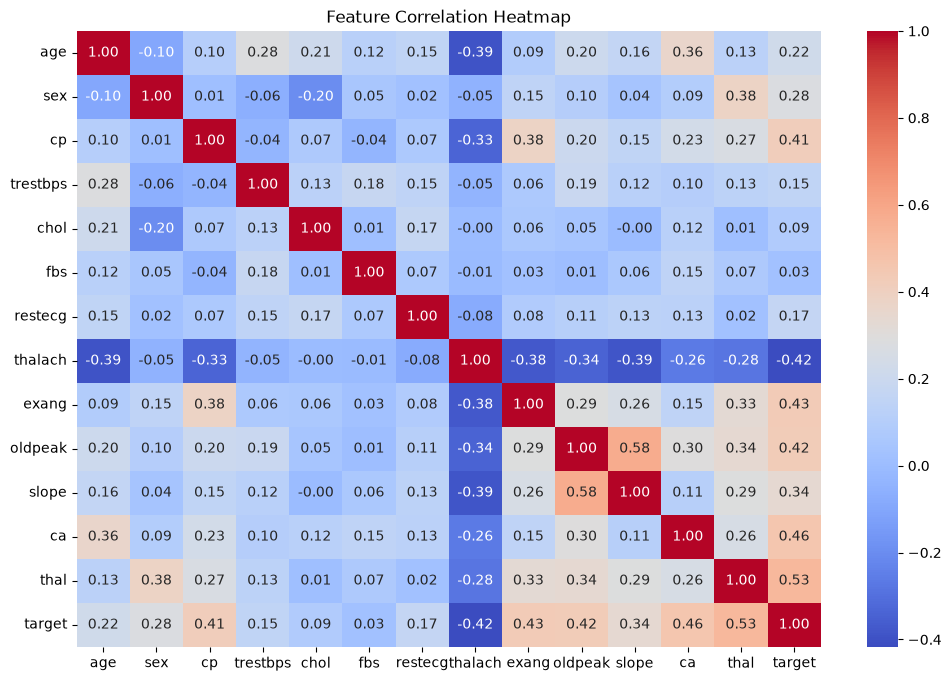

In [39]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")

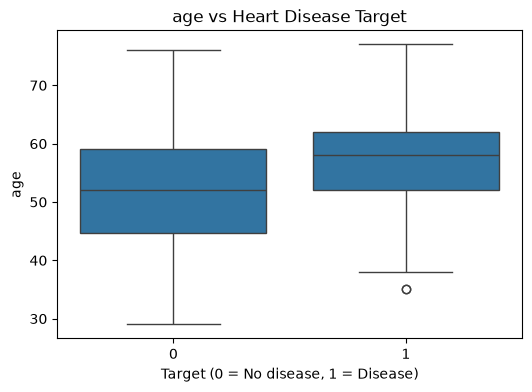

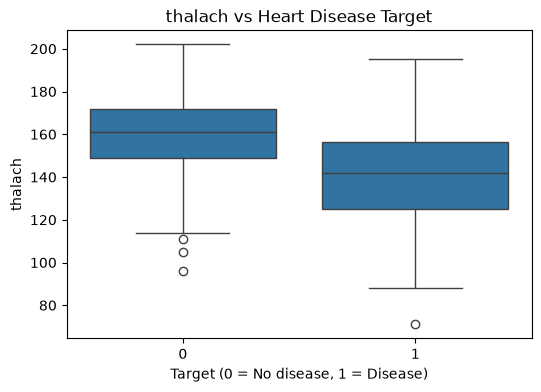

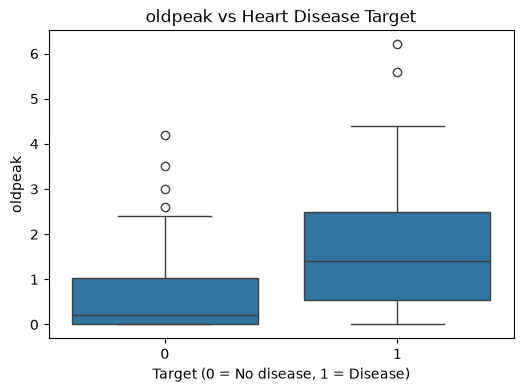

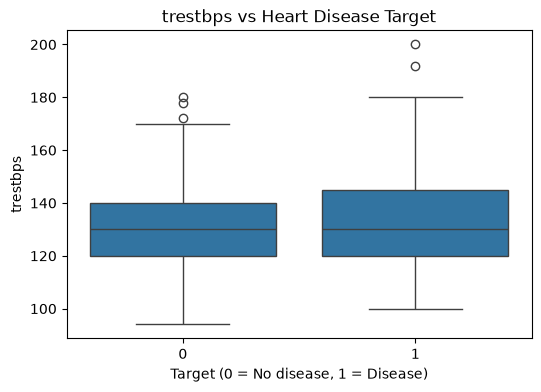

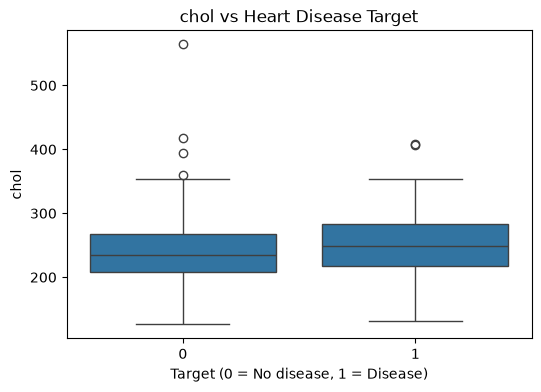

In [40]:
features = ["age", "thalach", "oldpeak", "trestbps", "chol"]

for feature in features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="target", y=feature)
    plt.title(f"{feature} vs Heart Disease Target")
    plt.xlabel("Target (0 = No disease, 1 = Disease)")

In [41]:
print(df["target"].value_counts())
print(df[["ca", "thal"]].isnull().sum())
print(df.isnull().sum().sort_values(ascending=False))

target
0    164
1    139
Name: count, dtype: int64
ca      4
thal    2
dtype: int64
ca          4
thal        2
cp          0
trestbps    0
age         0
sex         0
fbs         0
chol        0
restecg     0
thalach     0
oldpeak     0
exang       0
slope       0
target      0
dtype: int64


In [42]:
# Scikit learn Processing

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [44]:
X = df.drop(columns=["target"]).copy()
y = df["target"].astype(int)

numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg", "exang",
    "slope", "ca", "thal"
]


In [45]:
for col in numeric_features + categorical_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")


In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Preprocessing pipeline ready!")

Training data: (242, 13)
Testing data: (61, 13)
Preprocessing pipeline ready!


In [47]:
# Train the Model

In [48]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [49]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    )
}

pipelines = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline

    print(name, "trained successfully!")

Logistic Regression trained successfully!


Random Forest trained successfully!


In [50]:
results = []

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.869,0.812,0.929,0.867,0.966
1,Random Forest,0.885,0.818,0.964,0.885,0.946


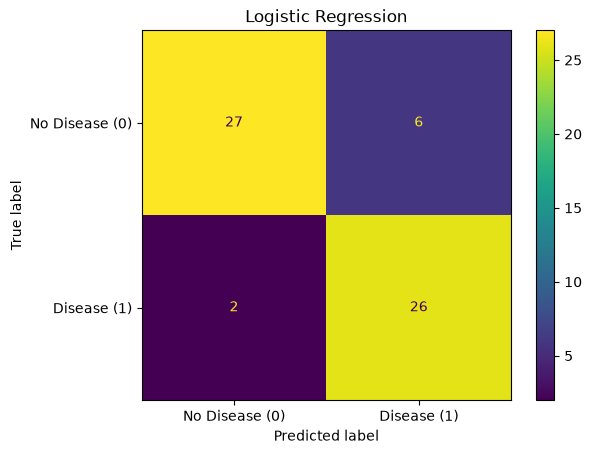


Logistic Regression
              precision    recall  f1-score   support

  No Disease       0.93      0.82      0.87        33
     Disease       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



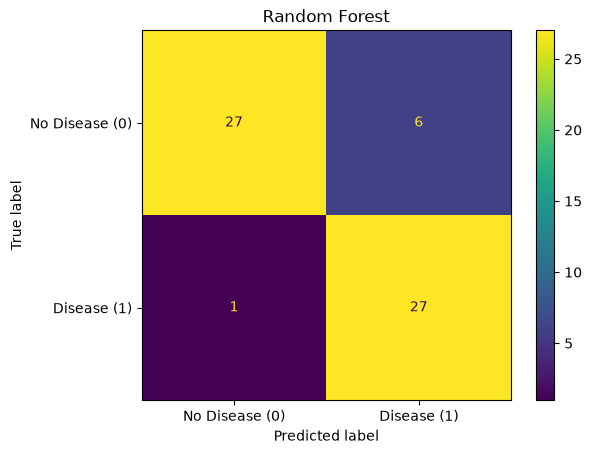


Random Forest
              precision    recall  f1-score   support

  No Disease       0.96      0.82      0.89        33
     Disease       0.82      0.96      0.89        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.90      0.89      0.89        61



In [ ]:
for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Disease (0)", "Disease (1)"]
    )

    disp.plot()
    plt.title(name)
    plt.show()

    print(f"\n{name}")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Disease", "Disease"],
        zero_division=0
    ))

In [52]:
import os
import joblib

os.makedirs("models", exist_ok=True)

for name, pipeline in pipelines.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(pipeline, os.path.join("models", filename))

print("Models saved successfully!")

Models saved successfully!
